In [1]:
import sys, json; sys.path.insert(0, '..')
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
from src.utils.config import *
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)

# 05 Customer segmentation (K-Means)

,k,inertia,silhouette
0,2,56091.7,0.1189
1,3,50746.7,0.1255
2,4,46817.8,0.1194
3,5,43549.6,0.1239
4,6,40965.0,0.1250
5,7,38873.4,0.1244
6,8,37332.2,0.1273
7,9,36083.0,0.1167
8,10,34856.6,0.1206


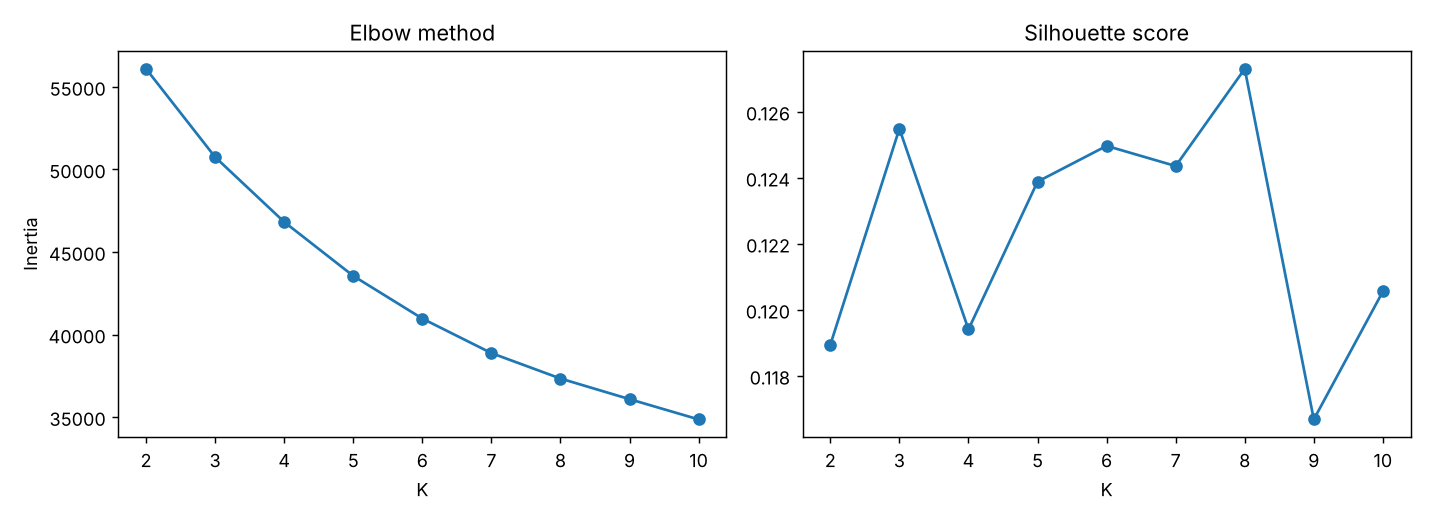

In [2]:
rep = json.load(open(REPORTS/'model_report.json'))['segmentation_k_search']; display(pd.DataFrame(rep)); display(Image(filename=str(FIGURES/'model_segmentation_k.png')))

**Elbow and silhouette are both flat.** Silhouette is 0.12 for every K from 2 to 10 and the elbow has no clear bend. The honest conclusion: **the customers do not form natural clusters.** K=5 was picked for business usability. These segments are a way to slice the base, not a discovery.

In [3]:
s = pd.read_csv(PROCESSED/'customer_scores.csv').merge(pd.read_csv(PROCESSED/'customer_features.csv'), on='customer_id')
s.groupby('segment_name').agg(customers=('customer_id','size'), engagement=('engagement_score','mean'), minutes_per_session=('avg_watch_time_per_session','mean'), tenure_years=('customer_tenure_days', lambda x: x.mean()/365), plan_price=('plan_price','mean'), tickets=('support_ticket_count','mean'), avg_clv=('customer_lifetime_value','mean'), churn=('churned','mean')).round(2)

,customers,engagement,minutes_per_session,tenure_years,plan_price,tickets,avg_clv,churn
segment_name,,,,,,,,
Budget Basic Subscribers,2008,58.40,50.54,4.22,7.40,0.51,96.46,0.28
Disengaged Drifters,1417,24.04,37.21,3.65,14.03,0.65,189.29,0.31
New & Highly Engaged,854,70.12,48.45,1.49,13.18,0.63,111.50,0.20
Premium Loyalists,2225,59.94,51.75,4.23,18.78,0.47,259.61,0.22
Support-Heavy Regulars,1496,54.85,49.05,3.90,13.11,1.73,174.88,0.21


In [4]:
d = json.load(open(REPORTS/'model_report.json'))['segmentation']['descriptions']
for k, v in d.items(): display(Markdown(f'**{k}**: {v}'))

**Premium Loyalists**: Long-tenured, highest plan price and lifetime value.

**Disengaged Drifters**: Lowest engagement and the highest churn: watching little, drifting away.

**Support-Heavy Regulars**: Contact support far more than anyone else; satisfied after resolution.

**New & Highly Engaged**: Newest customers who watch the most; the future of the base.

**Budget Basic Subscribers**: Cheapest plans, more payment failures, low lifetime value; price-sensitive.